Loaded 14 runs from: C:\Users\wimi\Desktop\Phd\Messungen\Kinetics\MM_kinetic_fit\Fit_Product_Inhibition\upload\data
==== Global fit (all runs) ====
Vmax=12.6012, KM=1195.9, KI=151.448
SSR=70386.6, MSE=525.273, R2=0.994565, R2_adj=0.99444
Reduced chi^2 (global) ~ 0.848
AIC (global) = 845.365
BIC (global) = 854.059

==== Leave-one-out over runs ====
[left-out #00] 1142.csv   | 1142.csv                  R2_val= 0.992, chi2_red_val~  1.20, AIC_train=817.3, BIC_train=825.8
[left-out #01] 1273.csv   | 1273.csv                  R2_val= 0.991, chi2_red_val~  2.50, AIC_train=751.5, BIC_train=760.0
[left-out #02] 1513.csv   | 1513.csv                  R2_val= 0.999, chi2_red_val~  0.20, AIC_train=804.9, BIC_train=813.5
[left-out #03] 1795.csv   | 1795.csv                  R2_val= 0.406, chi2_red_val~  2.99, AIC_train=824.1, BIC_train=832.7
[left-out #04] 273        | 273_1.csv                 R2_val= 0.982, chi2_red_val~  0.68, AIC_train=778.1, BIC_train=786.5
[left-out #05] 273        | 273_2.c

C:\Users\wimi\AppData\Local\Temp\ipykernel_31272\410164464.py:53: RuntimeWarning: overflow encountered in exp
  arg = (c0 / ((1 + c0 / ki) / (1 / km - 1 / ki))) * np.exp(
C:\Users\wimi\AppData\Local\Temp\ipykernel_31272\410164464.py:53: RuntimeWarning: overflow encountered in multiply
  arg = (c0 / ((1 + c0 / ki) / (1 / km - 1 / ki))) * np.exp(


  Vmax: 12.601  (profile CI: 10.357 – 14.842)
  Km: 1195.9  (profile CI: 889.28 – 1642.4)


C:\Users\wimi\AppData\Local\Temp\ipykernel_31272\410164464.py:52: RuntimeWarning: divide by zero encountered in double_scalars
  term1 = (1 + c0 / ki) / (1 / km - 1 / ki)
C:\Users\wimi\AppData\Local\Temp\ipykernel_31272\410164464.py:52: RuntimeWarning: invalid value encountered in double_scalars
  term1 = (1 + c0 / ki) / (1 / km - 1 / ki)
C:\Users\wimi\AppData\Local\Temp\ipykernel_31272\410164464.py:53: RuntimeWarning: divide by zero encountered in double_scalars
  arg = (c0 / ((1 + c0 / ki) / (1 / km - 1 / ki))) * np.exp(
C:\Users\wimi\AppData\Local\Temp\ipykernel_31272\410164464.py:53: RuntimeWarning: invalid value encountered in double_scalars
  arg = (c0 / ((1 + c0 / ki) / (1 / km - 1 / ki))) * np.exp(
C:\Users\wimi\AppData\Local\Temp\ipykernel_31272\410164464.py:54: RuntimeWarning: divide by zero encountered in double_scalars
  (c0 - ((vmax / km) / (1 / km - 1 / ki)) * t) / term1


  Ki: 151.45  (profile CI: 128.15 – 151.45)


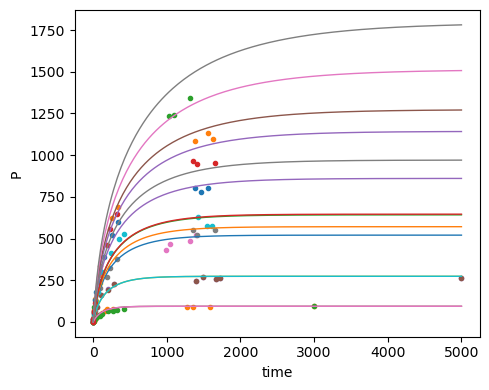

In [10]:
import os
import glob
import numpy as np
import pandas as pd
from scipy.optimize import least_squares
from scipy.special import lambertw
from scipy import stats
import matplotlib.pyplot as plt


### user input ####

USE_WEIGHTS = True
SIGMA_FLOOR = 0.01
T_FACTOR_95 = 1.96
N_STARTS = 100
Partition_coefficient = 31.74

###                V_max            K_M          K_P ##
param_bounds = [(0.1, 100.0), (0.1, 7000.0), (0.0, 2000.0)]


### function ####

def van_der_corput(n: int, base: int) -> float:
    vdc, denom = 0.0, 1.0
    while n:
        n, rem = divmod(n, base)
        denom *= base
        vdc += rem / denom
    return vdc


def hammersley_sequence(n_points: int, dim: int) -> np.ndarray:
    seq = np.zeros((n_points, dim), float)
    for i in range(n_points):
        seq[i, 0] = i / n_points
        for j in range(1, dim):
            seq[i, j] = van_der_corput(i, base=j + 1)
    return seq


def generate_initial_guesses(n_points: int, bounds: list[tuple[float, float]]) -> np.ndarray:
    h = hammersley_sequence(n_points, len(bounds))
    out = np.empty_like(h)
    for i, (lo, hi) in enumerate(bounds):
        out[:, i] = lo + (hi - lo) * h[:, i]
    return out


def model_fun(t, vmax, km, ki, c0):
    term1 = (1 + c0 / ki) / (1 / km - 1 / ki)
    arg = (c0 / ((1 + c0 / ki) / (1 / km - 1 / ki))) * np.exp(
        (c0 - ((vmax / km) / (1 / km - 1 / ki)) * t) / term1
    )
    return c0 - term1 * lambertw(arg).real


def residuals(params, all_t, all_P, all_c0, all_sigma):
    vmax, km, ki = params
    out = []
    for t, y, c0, sigma in zip(all_t, all_P, all_c0, all_sigma):
        yhat = model_fun(t, vmax, km, ki, c0)
        if not np.all(np.isfinite(yhat)):
            return np.full(sum(len(tt) for tt in all_t), 1e12)
        if USE_WEIGHTS:
            out.extend((yhat - y) / sigma)
        else:
            out.extend(yhat - y)
    return np.asarray(out)


def fit_multistart(all_t_local, all_P_local, all_c0_local, all_sigma_local, n_starts=N_STARTS):
    P_local = np.concatenate(all_P_local)
    sigma_local = np.concatenate(all_sigma_local)
    n_local = len(P_local)

    p0s = generate_initial_guesses(n_starts, param_bounds)

    best_res, best_ssr = None, np.inf
    for p0 in p0s:
        try:
            res = least_squares(
                residuals,
                p0,
                args=(all_t_local, all_P_local, all_c0_local, all_sigma_local),
                bounds=(lb, ub),
                method="trf",
                max_nfev=10000,
            )
            if not res.success:
                continue

            yhat = np.concatenate([model_fun(t, *res.x, c0) for t, c0 in zip(all_t_local, all_c0_local)])
            if not np.all(np.isfinite(yhat)):
                continue

            ssr = np.sum((P_local - yhat) ** 2)
            if ssr < best_ssr:
                best_ssr, best_res = ssr, res
        except Exception:
            pass

    if best_res is None:
        raise RuntimeError("All multi-start fits failed; check model_fun or bounds.")

    k = len(best_res.x)
    dof = n_local - k

    if USE_WEIGHTS:
        yhat = np.concatenate([model_fun(t, *best_res.x, c0) for t, c0 in zip(all_t_local, all_c0_local)])
        chi2 = np.sum(((P_local - yhat) / sigma_local) ** 2)
        chi2_red = chi2 / dof
    else:
        chi2_red = np.nan

    if best_ssr > 0:
        sigma2 = best_ssr / n_local
        aic = 2 * k + n_local * np.log(sigma2)
        bic = k * np.log(n_local) + n_local * np.log(sigma2)
    else:
        aic = np.nan
        bic = np.nan

    return best_res, best_ssr, chi2_red, aic, bic


### read data ###

if "__file__" in globals():
    BASE_DIR = os.path.dirname(os.path.abspath(__file__))
else:
    BASE_DIR = os.getcwd()

data_folder = os.path.join(BASE_DIR, "data")
csv_files = sorted(glob.glob(os.path.join(data_folder, "*.csv")))
if not csv_files:
    raise FileNotFoundError(f"No .csv files found in: {data_folder}")

groups: dict[str, list[str]] = {}
for f in csv_files:
    groups.setdefault(os.path.basename(f).split("_")[0], []).append(f)

all_t, all_P, all_c0, all_sigma, order_info = [], [], [], [], []

for prefix, files in groups.items():
    for f in files:
        df = pd.read_csv(f)
        if ("t" not in df.columns) or ("c_P" not in df.columns) or ("c_S" not in df.columns):
            continue

        t = df["t"].to_numpy(float)
        cP = df["c_P"].to_numpy(float)
        c0 = float(df["c_S"].iloc[0])

        P = (cP / Partition_coefficient * 0.2 / (1 - 0.2) + cP)

        if USE_WEIGHTS and "u95_total" in df.columns:
            sigma_95 = df["u95_total"].to_numpy(float)
            sigma = np.maximum(SIGMA_FLOOR, sigma_95 / T_FACTOR_95)
        else:
            sigma = np.ones_like(P)

        mask = np.isfinite(t) & np.isfinite(P) & np.isfinite(sigma)
        t, P, sigma = t[mask], P[mask], sigma[mask]
        if len(t) == 0:
            continue

        all_t.append(t)
        all_P.append(P)
        all_c0.append(c0)
        all_sigma.append(sigma)
        order_info.append((prefix, f))

if not all_t:
    raise RuntimeError("No usable runs loaded (missing required columns or all rows invalid).")

n_runs = len(all_t)
P_concat = np.concatenate(all_P)
sigma_concat = np.concatenate(all_sigma)
n_points = len(P_concat)

lb, ub = map(np.array, zip(*param_bounds))


best_result, best_ssr, chi2_red_global, aic_global, bic_global = fit_multistart(all_t, all_P, all_c0, all_sigma)

P_pred_best = np.concatenate([model_fun(t, *best_result.x, c0) for t, c0 in zip(all_t, all_c0)])
SSR = np.sum((P_concat - P_pred_best) ** 2)
MSE = SSR / n_points
SST = np.sum((P_concat - np.mean(P_concat)) ** 2)
k_params = len(best_result.x)
dof = n_points - k_params
R2 = 1 - SSR / SST if SST > 0 else np.nan
R2_adj = 1 - (1 - R2) * (n_points - 1) / (n_points - k_params - 1)

if SSR > 0:
    sigma2_global = SSR / n_points
    aic_global = 2 * k_params + n_points * np.log(sigma2_global)
    bic_global = k_params * np.log(n_points) + n_points * np.log(sigma2_global)
else:
    aic_global = np.nan
    bic_global = np.nan

vmax_hat, km_hat, ki_hat = best_result.x
print(f"Loaded {n_runs} runs from: {data_folder}")
print("==== Global fit (all runs) ====")
print(f"Vmax={vmax_hat:.6g}, KM={km_hat:.6g}, KI={ki_hat:.6g}")
print(f"SSR={SSR:.6g}, MSE={MSE:.6g}, R2={R2:.6g}, R2_adj={R2_adj:.6g}")
print(f"Reduced chi^2 (global) ~ {chi2_red_global:.3f}")
print(f"AIC (global) = {aic_global:.3f}")
print(f"BIC (global) = {bic_global:.3f}")


print("\n==== Leave-one-out over runs ====")
PRESS_total = 0.0
n_val_total = 0
chi2_val_total = 0.0
dof_val_total = 0

for i in range(n_runs):
    train_idx = [j for j in range(n_runs) if j != i]

    t_train = [all_t[j] for j in train_idx]
    P_train = [all_P[j] for j in train_idx]
    c0_train = [all_c0[j] for j in train_idx]
    s_train = [all_sigma[j] for j in train_idx]

    t_val, P_val, c0_val, s_val = all_t[i], all_P[i], all_c0[i], all_sigma[i]
    prefix_i, file_i = order_info[i]

    try:
        res_i, _, _, aic_train_i, bic_train_i = fit_multistart(
            t_train, P_train, c0_train, s_train, n_starts=N_STARTS
        )
    except RuntimeError as e:
        print(f"LOO fit failed for run {i} ({os.path.basename(file_i)}): {e}")
        continue

    P_pred_val = model_fun(t_val, *res_i.x, c0_val)
    SSR_val = np.sum((P_val - P_pred_val) ** 2)
    SST_val = np.sum((P_val - np.mean(P_val)) ** 2)
    R2_val = 1 - SSR_val / SST_val if SST_val > 0 else np.nan

    if USE_WEIGHTS:
        chi2_val = np.sum(((P_val - P_pred_val) / s_val) ** 2)
        chi2_red_val = chi2_val / len(P_val)
    else:
        chi2_red_val = np.nan

    PRESS_total += SSR_val
    n_val_total += len(P_val)
    if USE_WEIGHTS:
        chi2_val_total += chi2_val
        dof_val_total += len(P_val)

    print(
        f"[left-out #{i:02d}] {prefix_i:10s} | {os.path.basename(file_i):25s} "
        f"R2_val={R2_val:6.3f}, chi2_red_val~{chi2_red_val:6.2f}, "
        f"AIC_train={aic_train_i:.1f}, BIC_train={bic_train_i:.1f}"
    )

if n_val_total > 0:
    RMSE_LOO = np.sqrt(PRESS_total / n_val_total)
    SST_global = np.sum((P_concat - np.mean(P_concat)) ** 2)
    Q2 = 1 - PRESS_total / SST_global if SST_global > 0 else np.nan

    print("\n==== Global LOO metrics ====")
    print(f"PRESS = {PRESS_total:.6g}")
    print(f"RMSE_LOO = {RMSE_LOO:.6g}")
    print(f"Q2 = {Q2:.4f}")

    if USE_WEIGHTS and dof_val_total > 0:
        chi2_red_loo = chi2_val_total / dof_val_total
        print(f"chi2_red_LOO (global) ~ {chi2_red_loo:.3f}")
else:
    print("\nNo successful LOO fits; cannot compute global LOO metrics.")


J = best_result.jac
rss_w = 2.0 * best_result.cost
sigma2_hat = rss_w / dof

try:
    cov_theta = np.linalg.inv(J.T @ J) * sigma2_hat
    se = np.sqrt(np.diag(cov_theta))
    tval = stats.t.ppf(0.975, dof)
    print("\n95% CIs (Wald):")
    for name, est, err in zip(["Vmax", "KM", "KI"], best_result.x, se):
        lo = est - tval * err
        hi = est + tval * err
        print(f"  {name}: {est:.5g} ± {tval*err:.5g}  (CI: {lo:.5g} – {hi:.5g})")
except np.linalg.LinAlgError:
    print("\nCovariance matrix not invertible; Wald CIs unavailable.")


best_chi2 = 2.0 * best_result.cost
chi2_threshold = best_chi2 + stats.chi2.ppf(0.95, df=1)


def fit_with_fixed_param(fixed_idx: int, fixed_value: float):
    full_best = best_result.x.copy()
    p0_free = [full_best[j] for j in range(len(full_best)) if j != fixed_idx]
    lb_free = [param_bounds[j][0] for j in range(len(param_bounds)) if j != fixed_idx]
    ub_free = [param_bounds[j][1] for j in range(len(param_bounds)) if j != fixed_idx]

    def residuals_fixed(free_params):
        full = full_best.copy()
        k = 0
        for j in range(len(full)):
            if j == fixed_idx:
                full[j] = fixed_value
            else:
                full[j] = free_params[k]
                k += 1
        return residuals(full, all_t, all_P, all_c0, all_sigma)

    try:
        res = least_squares(
            residuals_fixed,
            p0_free,
            bounds=(lb_free, ub_free),
            method="trf",
            max_nfev=5000,
        )
        return res if res.success else None
    except Exception:
        return None


def profile_ci_for_param(idx: int, n_grid: int = 40):
    theta_hat = float(best_result.x[idx])
    lo_b, hi_b = param_bounds[idx]

    grid_lo = np.linspace(theta_hat, lo_b, n_grid)
    th_lo, chi_lo = [], []
    for val in grid_lo:
        r = fit_with_fixed_param(idx, float(val))
        if r is None:
            continue
        c2 = 2.0 * r.cost
        if np.isfinite(c2):
            th_lo.append(val)
            chi_lo.append(c2)

    lower_ci = lo_b
    if th_lo:
        th_lo = np.array(th_lo)
        chi_lo = np.array(chi_lo)
        ok = chi_lo <= chi2_threshold
        lower_ci = float(np.min(th_lo[ok])) if np.any(ok) else theta_hat

    grid_hi = np.linspace(theta_hat, hi_b, n_grid)
    th_hi, chi_hi = [], []
    for val in grid_hi:
        r = fit_with_fixed_param(idx, float(val))
        if r is None:
            continue
        c2 = 2.0 * r.cost
        if np.isfinite(c2):
            th_hi.append(val)
            chi_hi.append(c2)

    upper_ci = hi_b
    if th_hi:
        th_hi = np.array(th_hi)
        chi_hi = np.array(chi_hi)
        ok = chi_hi <= chi2_threshold
        upper_ci = float(np.max(th_hi[ok])) if np.any(ok) else theta_hat

    return float(lower_ci), float(upper_ci)


print("\nProfile likelihood 95% CIs:")
for idx, name in enumerate(["Vmax", "Km", "Ki"]):
    lo, hi = profile_ci_for_param(idx, n_grid=40)
    print(f"  {name}: {best_result.x[idx]:.5g}  (profile CI: {lo:.5g} – {hi:.5g})")


# ---- plot ----
plt.figure(figsize=(5, 4))

for t, P in zip(all_t, all_P):
    plt.plot(t, P, "o", ms=3)

for t, c0 in zip(all_t, all_c0):
    tfit = np.linspace(float(np.min(t)), 5000, 200)
    Pfit = model_fun(tfit, *best_result.x, c0)
    plt.plot(tfit, Pfit, "-", lw=1)

plt.xlabel("time")
plt.ylabel("P")
plt.tight_layout()
plt.show()